# Phase 2 Pre-check

classical models only, no circuits. it answers four questions before the big runs:

1. pls: how much do 8, 16 and 32 pls components give, and is there anything for a feature search to find among them?
2. 16 inputs on 8 qubits: does reading two numbers per qubit help, for pca and pls?
3. raw clip: can 8 of the 512 clip numbers, picked by aco, greedy or random search, compete with pca and pls?
4. one summary table.

every circuit without entanglers equals its classical twin, so the twin tells us what a circuit can reach on each input. same rules as phase 1: picking uses search-train and the inner fitness split only, val is used for the final numbers.

In [1]:
import os
# one thread per process, set before numpy loads
os.environ["OMP_NUM_THREADS"] = "1"
import time
import json
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

seed = 0
np.random.seed(seed)

prep_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-feature-dataset/prep"
clip_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-clip-dataset/features"
out_dir = "/kaggle/working/precheck"
os.makedirs(out_dir, exist_ok=True)

c_grid = [0.01, 0.1, 1.0]   # logistic regression strength, picked on val like the phase 1 baselines
n_pls = 32
low, high = 0.5, 99.5       # angle range from search-train percentiles, same as phase 1
# raw clip search
n_runs = 3
budget = 4000               # distinct subsets per run, about what greedy on 512 costs
pop_size = 20               # ants per round, random subsets per round
top_k = 3
rho = 0.1
tau_min = 0.1
tau_max = 5.0
hint_power = 1.0            # aco with hint: chance ~ pheromone x (strength - 0.5)

In [2]:
angles, meta = {}, {}
for split in ["train", "val"]:
    angles[split] = np.load(f"{prep_dir}/ffpp_{split}_angles32.npy").astype(np.float64)
    meta[split] = pd.read_csv(f"{prep_dir}/ffpp_{split}_rows.csv")

is_inner = np.load(f"{prep_dir}/ffpp_train_is_inner.npy").astype(bool)
comp = pd.read_csv(f"{prep_dir}/per_component_auc.csv")
pca_order = comp.sort_values("strength_search_train", ascending=False)["component"].tolist()
first8 = list(range(8))
best8 = sorted(pca_order[:8])
greedy8 = [3, 4, 8, 9, 10, 16, 17, 21]   # phase 1 greedy selector

clip = {}
for split in ["train", "val"]:
    clip_rows = pd.read_csv(f"{clip_dir}/ffpp_{split}_rows.csv")
    assert (clip_rows["path"].to_numpy() == meta[split]["path"].to_numpy()).all(), split
    x = np.load(f"{clip_dir}/ffpp_{split}_clip.npy").astype(np.float64)
    clip[split] = x / np.linalg.norm(x, axis=1, keepdims=True)

y_train = meta["train"]["label"].to_numpy()
y_val = meta["val"]["label"].to_numpy()
# a video is (method, video_id), the 4 fakes of one pair share a video_id
val_video = meta["val"].groupby(["method", "video_id"]).ngroup().to_numpy()
st = ~is_inner

print("train frames:", len(y_train), " search-train:", st.sum(), " inner:", is_inner.sum(), " val videos:", val_video.max() + 1)

train frames: 46076  search-train: 39164  inner: 6912  val videos: 700


## fitness frames

same 2000 frames as the phase 1 search (1000 real, 1000 fake, at most 2 per real video and 1 per fake video), scored on the inner fitness frames.

In [3]:
search_idx = np.where(~is_inner)[0]
inner_idx = np.where(is_inner)[0]

st_rows = meta["train"].iloc[search_idx].copy()
st_rows["row"] = search_idx
real_pick = st_rows[st_rows["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
fake_pick = st_rows[st_rows["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
rng = np.random.default_rng(0)
sub = np.concatenate([rng.choice(real_pick, 1000, replace=False), rng.choice(fake_pick, 1000, replace=False)])

## helpers

the same scoring as phase 1, plus the twin for two numbers per qubit. a qubit that gets RY(a) then RZ(b) has the bloch vector (sin a cos b, sin a sin b, cos a), and after any trainable rotation its <z> is a linear function of those 3 numbers. so that circuit's twin is logistic regression on 3 features per qubit. qubit q gets inputs q and q + 8.

In [4]:
def video_level(prob):
    df = pd.DataFrame({"video": val_video, "p": prob, "y": y_val})
    g = df.groupby("video").agg(p=("p", "mean"), y=("y", "first"))
    return g["p"].to_numpy(), g["y"].to_numpy()


def bootstrap_ci(p, y, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    aucs = []
    while len(aucs) < n:
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5])


def score(prob):
    pv, yv = video_level(prob)
    lo, hi = bootstrap_ci(pv, yv)
    return {"frame auc": roc_auc_score(y_val, prob), "video auc": roc_auc_score(yv, pv), "ci low": lo, "ci high": hi}


def sincos(a):
    return np.concatenate([np.sin(a), np.cos(a)], axis=1)


def bloch(a):
    # 16 angles on 8 qubits: qubit q gets RY(a[q]) then RZ(a[q + 8])
    ay, az = a[:, :8], a[:, 8:16]
    return np.concatenate([np.sin(ay) * np.cos(az), np.sin(ay) * np.sin(az), np.cos(ay)], axis=1)


def logreg(c):
    return make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000))


def to_angles(z_train, z_val):
    # range from search-train only
    lo = np.percentile(z_train[st], low, axis=0)
    hi = np.percentile(z_train[st], high, axis=0)
    return {"train": np.clip((z_train - lo) / (hi - lo), 0.0, 1.0) * np.pi,
            "val": np.clip((z_val - lo) / (hi - lo), 0.0, 1.0) * np.pi}


def strengths(z_train):
    # each column's own auc on search-train, either direction
    out = []
    for j in range(z_train.shape[1]):
        auc = roc_auc_score(y_train[st], z_train[st, j])
        out.append(max(auc, 1 - auc))
    return np.array(out)


table = []


def tune(part, inp, model, xt, xv, weights):
    # one fit per setting on all of train, keep the best val video auc
    best = None
    for c in c_grid:
        prob = logreg(c).fit(xt, y_train).predict_proba(xv)[:, 1]
        pv, yv = video_level(prob)
        auc = roc_auc_score(yv, pv)
        if best is None or auc > best[1]:
            best = (c, auc, prob)
    row = {"part": part, "input": inp, "model": model, "weights": weights, "setting": best[0]}
    row.update(score(best[2]))
    table.append(row)
    print(f"{inp:28s} {model:22s} video auc {row['video auc']:.3f} ({row['ci low']:.3f} to {row['ci high']:.3f})")
    return row


def greedy(a, k, fit_rows, score_rows, label):
    # adds the column that most raises the twin's auc, phase 1 rule (C = 1)
    selected, n_fits = [], 0
    for step in range(k):
        best = None
        for j in range(a.shape[1]):
            if j in selected:
                continue
            cols = selected + [j]
            model = logreg(1.0).fit(sincos(a[fit_rows][:, cols]), y_train[fit_rows])
            auc = roc_auc_score(y_train[score_rows], model.predict_proba(sincos(a[score_rows][:, cols]))[:, 1])
            n_fits += 1
            if best is None or auc > best[1]:
                best = (j, auc)
        selected.append(best[0])
    print(f"greedy on {label}: added in order {selected}, inner auc {best[1]:.3f}, {n_fits} fits")
    return selected, n_fits

## part 1: pls

pls fitted with 32 components on search-train only, so neither the inner split nor val is seen. pls builds its components one after another, so its first 8 are the same as an 8-component fit.

In [5]:
pls = PLSRegression(n_components=n_pls, scale=False)
pls.fit(clip["train"][st], y_train[st])
pls_a = to_angles(pls.transform(clip["train"]), pls.transform(clip["val"]))

pls_strength = strengths(pls_a["train"])
pls_comp = pd.DataFrame({"component": range(n_pls), "strength_search_train": pls_strength})
pls_comp.to_csv(f"{out_dir}/pls_per_component_auc.csv", index=False)
print("pls strength, first 8: ", np.round(pls_strength[:8], 3))
print("pls strength, 9 to 16: ", np.round(pls_strength[8:16], 3))
print("pls strength, 17 to 32 max:", round(pls_strength[16:].max(), 3))

pls strength, first 8:  [0.701 0.627 0.612 0.585 0.584 0.582 0.594 0.558]
pls strength, 9 to 16:  [0.572 0.568 0.555 0.552 0.554 0.55  0.547 0.542]
pls strength, 17 to 32 max: 0.534


In [6]:
at, av = pls_a["train"], pls_a["val"]
tune("pls", "pls 8", "logistic regression", at[:, :8], av[:, :8], 9)
tune("pls", "pls 8", "sin/cos twin", sincos(at[:, :8]), sincos(av[:, :8]), 17)
tune("pls", "pls 16", "logistic regression", at[:, :16], av[:, :16], 17)
tune("pls", "pls 16 on 8 qubits", "2-per-qubit twin", bloch(at[:, :16]), bloch(av[:, :16]), 25)
tune("pls", "pls 32", "logistic regression", at, av, 33)

pls 8                        logistic regression    video auc 0.840 (0.808 to 0.871)
pls 8                        sin/cos twin           video auc 0.842 (0.809 to 0.872)
pls 16                       logistic regression    video auc 0.871 (0.839 to 0.898)
pls 16 on 8 qubits           2-per-qubit twin       video auc 0.870 (0.838 to 0.897)
pls 32                       logistic regression    video auc 0.882 (0.853 to 0.907)


{'part': 'pls',
 'input': 'pls 32',
 'model': 'logistic regression',
 'weights': 33,
 'setting': 0.01,
 'frame auc': np.float64(0.85028462437805),
 'video auc': np.float64(0.8824362244897959),
 'ci low': np.float64(0.8534109952240422),
 'ci high': np.float64(0.9074363954997096)}

## greedy over the 32 pls components

the phase 1 greedy rule: the twin trained on search-train, scored on the inner split. if greedy mostly picks the first 8, a feature search on pls has little to find.

In [7]:
pls_greedy, _ = greedy(pls_a["train"], 8, st, is_inner, "32 pls")
pls_greedy8 = sorted(pls_greedy)
print("of the greedy 8, in the first 8:", sum(j < 8 for j in pls_greedy8))
tune("pls", f"pls greedy 8 {pls_greedy8}", "sin/cos twin", sincos(at[:, pls_greedy8]), sincos(av[:, pls_greedy8]), 17)

greedy on 32 pls: added in order [0, 1, 2, 3, 8, 6, 14, 7], inner auc 0.837, 228 fits
of the greedy 8, in the first 8: 6
pls greedy 8 [0, 1, 2, 3, 6, 7, 8, 14] sin/cos twin           video auc 0.828 (0.793 to 0.859)


{'part': 'pls',
 'input': 'pls greedy 8 [0, 1, 2, 3, 6, 7, 8, 14]',
 'model': 'sin/cos twin',
 'weights': 17,
 'setting': 0.1,
 'frame auc': np.float64(0.8046999838532198),
 'video auc': np.float64(0.827844387755102),
 'ci low': np.float64(0.7934501145529907),
 'ci high': np.float64(0.8585883664863138)}

## part 2: 16 inputs on 8 qubits, pca

the 8-input rows repeat phase 1 for comparison. best 16 are the 16 strongest components on search-train.

In [8]:
at, av = angles["train"], angles["val"]
best16 = pca_order[:16]
first16 = list(range(16))
for label, cols in [("pca first 8", first8), ("pca best 8", best8), ("pca greedy 8", greedy8)]:
    tune("pca", label, "sin/cos twin", sincos(at[:, cols]), sincos(av[:, cols]), 17)
for label, cols in [("pca first 16", first16), ("pca best 16", best16)]:
    tune("pca", label, "logistic regression", at[:, cols], av[:, cols], 17)
    tune("pca", label + " on 8 qubits", "2-per-qubit twin", bloch(at[:, cols]), bloch(av[:, cols]), 25)

pca first 8                  sin/cos twin           video auc 0.645 (0.595 to 0.693)
pca best 8                   sin/cos twin           video auc 0.713 (0.667 to 0.754)
pca greedy 8                 sin/cos twin           video auc 0.716 (0.669 to 0.757)
pca first 16                 logistic regression    video auc 0.689 (0.641 to 0.733)
pca first 16 on 8 qubits     2-per-qubit twin       video auc 0.694 (0.648 to 0.740)
pca best 16                  logistic regression    video auc 0.744 (0.704 to 0.781)
pca best 16 on 8 qubits      2-per-qubit twin       video auc 0.742 (0.701 to 0.781)


## part 3: raw clip, 8 of 512

each of the 512 clip numbers (after scaling the vector to length 1) gets its own angle range from search-train. best 8 are the 8 strongest numbers on their own.

In [9]:
raw_a = to_angles(clip["train"], clip["val"])
raw_strength = strengths(raw_a["train"])
pd.DataFrame({"dim": range(512), "strength_search_train": raw_strength}).to_csv(f"{out_dir}/raw_per_dim_auc.csv", index=False)
raw_best8 = sorted(np.argsort(-raw_strength)[:8].tolist())
print("strongest single clip numbers:", np.round(np.sort(raw_strength)[::-1][:8], 3))
print("dims with strength above 0.6:", (raw_strength > 0.6).sum())

at, av = raw_a["train"], raw_a["val"]
tune("raw", f"raw best 8 {raw_best8}", "sin/cos twin", sincos(at[:, raw_best8]), sincos(av[:, raw_best8]), 17)

strongest single clip numbers: [0.619 0.609 0.607 0.604 0.598 0.595 0.593 0.588]
dims with strength above 0.6: 4
raw best 8 [26, 93, 124, 204, 318, 350, 385, 481] sin/cos twin           video auc 0.710 (0.662 to 0.753)


{'part': 'raw',
 'input': 'raw best 8 [26, 93, 124, 204, 318, 350, 385, 481]',
 'model': 'sin/cos twin',
 'weights': 17,
 'setting': 1.0,
 'frame auc': np.float64(0.6875001121304182),
 'video auc': np.float64(0.7099107142857143),
 'ci low': np.float64(0.6619385873220761),
 'ci high': np.float64(0.7532689343859575)}

## search on raw clip

fitness is the sin/cos twin (C = 1) trained on the 2000 fitness frames and scored by auc on the inner frames. it takes milliseconds, so every method gets 4000 distinct subsets per run. greedy uses the same fitness, so all four are scored the same way.

- random: 8 distinct numbers, uniform.
- aco: each ant picks 8 numbers one at a time, chance set by pheromone. after each round pheromone evaporates, the round's best and the best so far each add 1, values stay between `tau_min` and `tau_max` (the phase 1 aco, mask part only). no hint.
- aco + hint: the same, with each number's chance also multiplied by its own strength minus 0.5 (search-train only). greedy uses this kind of information, so this is the fairer rival to greedy.

In [10]:
fit_a = raw_a["train"][sub]
inner_a = raw_a["train"][inner_idx]
y_fit = y_train[sub]
y_inner = y_train[inner_idx]
hint = np.maximum(raw_strength - 0.5, 1e-3) ** hint_power


def fitness(mask):
    model = logreg(1.0).fit(sincos(fit_a[:, mask]), y_fit)
    return roc_auc_score(y_inner, model.predict_proba(sincos(inner_a[:, mask]))[:, 1])


def evaluate(masks, cache, log, method, run, limit=budget):
    # a subset seen before costs nothing and is not counted
    n_new = 0
    fit = []
    for m in masks:
        key = tuple(sorted(m))
        if key not in cache and len(cache) < limit:
            cache[key] = fitness(list(key))
            log.append({"method": method, "run": run, "eval": len(cache), "mask": ".".join(map(str, key)), "fitness": cache[key]})
            n_new += 1
        fit.append(cache.get(key))
    return fit, n_new


def random_search(run):
    rng = np.random.default_rng(6000 + run)
    cache, log = {}, []
    while len(cache) < budget:
        masks = [rng.choice(512, 8, replace=False).tolist() for _ in range(pop_size)]
        evaluate(masks, cache, log, "random", run)
    return cache, log


def aco(run, use_hint):
    method = "aco + hint" if use_hint else "aco"
    rng = np.random.default_rng(4000 + run)
    tau = np.ones(512)
    cache, log = {}, []
    best = None
    stale = 0
    while len(cache) < budget:
        masks = []
        for _ in range(pop_size):
            w = tau * hint if use_hint else tau.copy()
            mask = []
            for _ in range(8):
                j = int(rng.choice(512, p=w / w.sum()))
                mask.append(j)
                w[j] = 0
            masks.append(mask)
        fit, n_new = evaluate(masks, cache, log, method, run)
        round_best = None
        for f, m in zip(fit, masks):
            if f is not None and (round_best is None or f > round_best[0]):
                round_best = (f, m)
        if round_best is None:
            break
        if best is None or round_best[0] > best[0]:
            best = round_best
        tau *= 1 - rho
        tau[round_best[1]] += 1
        tau[best[1]] += 1
        tau = np.clip(tau, tau_min, tau_max)
        if n_new == 0:
            stale += 1
        else:
            stale = 0
        if stale >= 20:
            print(f"{method} run {run} stopped early at {len(cache)} subsets")
            break
    return cache, log


def run_job(job):
    method, run = job
    t0 = time.time()
    if method == "random":
        cache, log = random_search(run)
    else:
        cache, log = aco(run, method == "aco + hint")
    return method, run, cache, log, time.time() - t0

In [11]:
# greedy on the fitness frames, counted like the searches
t0 = time.time()
cache, glog = {}, []
selected = []
for step in range(8):
    cands = [selected + [j] for j in range(512) if j not in selected]
    # greedy has no budget cap, its cost is reported instead
    fit, _ = evaluate(cands, cache, glog, "greedy", 0, limit=10 ** 6)
    selected = cands[int(np.argmax(fit))]
raw_greedy8 = sorted(selected)
print(f"greedy: {raw_greedy8}, inner auc {cache[tuple(raw_greedy8)]:.3f}, {len(cache)} subsets, {time.time() - t0:.0f} s")

jobs = [(m, r) for r in range(n_runs) for m in ["random", "aco", "aco + hint"]]
with mp.get_context("fork").Pool(os.cpu_count()) as pool:
    results = pool.map(run_job, jobs)

caches = {(m, r): c for m, r, c, _, _ in results}
log = pd.DataFrame(glog + [row for _, _, _, l, _ in results for row in l])
log.to_csv(f"{out_dir}/raw_search_log.csv", index=False)
for m, r, c, _, sec in results:
    print(f"{m:10s} run {r}: {len(c)} subsets, best inner auc {max(c.values()):.3f}, {sec:.0f} s")

greedy: [77, 209, 266, 310, 318, 339, 385, 459], inner auc 0.740, 4068 subsets, 36 s
random     run 0: 4000 subsets, best inner auc 0.681, 68 s
aco        run 0: 4000 subsets, best inner auc 0.727, 70 s
aco + hint run 0: 4000 subsets, best inner auc 0.736, 71 s
random     run 1: 4000 subsets, best inner auc 0.680, 69 s
aco        run 1: 4000 subsets, best inner auc 0.726, 70 s
aco + hint run 1: 4000 subsets, best inner auc 0.728, 71 s
random     run 2: 4000 subsets, best inner auc 0.685, 69 s
aco        run 2: 4000 subsets, best inner auc 0.723, 70 s
aco + hint run 2: 4000 subsets, best inner auc 0.736, 45 s


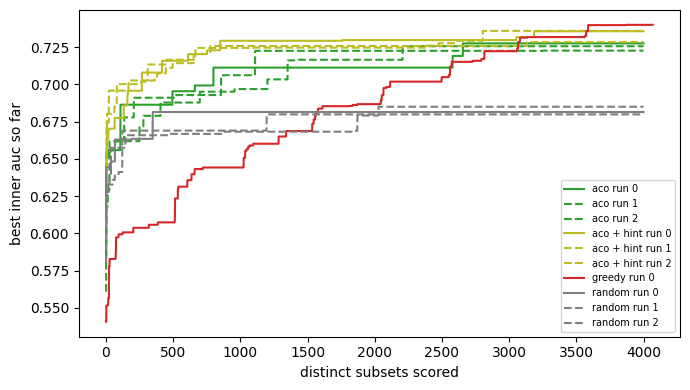

In [12]:
colors = {"random": "tab:gray", "aco": "tab:green", "aco + hint": "tab:olive", "greedy": "tab:red"}
plt.figure(figsize=(7, 4))
for (method, run), g in log.groupby(["method", "run"]):
    g = g.sort_values("eval")
    style = "-" if run == 0 else "--"
    plt.plot(g["eval"], g["fitness"].cummax(), style, color=colors[method], label=f"{method} run {run}")
plt.xlabel("distinct subsets scored")
plt.ylabel("best inner auc so far")
plt.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{out_dir}/raw_convergence.png", dpi=150)
plt.show()

## final pick per run

each run's top 3 subsets get the twin trained on all of train, the best on val is the run's pick. greedy's 8 go through the same step.

In [13]:
at, av = raw_a["train"], raw_a["val"]
tune("raw", f"raw greedy 8 {raw_greedy8}", "sin/cos twin", sincos(at[:, raw_greedy8]), sincos(av[:, raw_greedy8]), 17)

picks = []
for (method, run), c in caches.items():
    top = sorted(c.items(), key=lambda t: t[1], reverse=True)[:top_k]
    best = None
    for key, inner_auc in top:
        cols = list(key)
        prob = logreg(1.0).fit(sincos(at[:, cols]), y_train).predict_proba(sincos(av[:, cols]))[:, 1]
        pv, yv = video_level(prob)
        auc = roc_auc_score(yv, pv)
        if best is None or auc > best[1]:
            best = (cols, auc, inner_auc)
    picks.append({"method": method, "run": run, "mask": best[0], "inner auc": best[2], "val video auc": best[1]})
    tune("raw", f"raw {method} run {run} {best[0]}", "sin/cos twin", sincos(at[:, best[0]]), sincos(av[:, best[0]]), 17)

picks = pd.DataFrame(picks)
picks.to_csv(f"{out_dir}/raw_final_picks.csv", index=False)

raw greedy 8 [77, 209, 266, 310, 318, 339, 385, 459] sin/cos twin           video auc 0.720 (0.674 to 0.760)
raw random run 0 [72, 81, 108, 124, 128, 194, 209, 314] sin/cos twin           video auc 0.663 (0.608 to 0.714)
raw aco run 0 [86, 121, 124, 138, 252, 310, 318, 445] sin/cos twin           video auc 0.699 (0.653 to 0.742)
raw aco + hint run 0 [22, 70, 72, 124, 209, 318, 323, 339] sin/cos twin           video auc 0.714 (0.666 to 0.756)
raw random run 1 [71, 74, 166, 197, 298, 370, 391, 418] sin/cos twin           video auc 0.662 (0.611 to 0.709)
raw aco run 1 [72, 88, 124, 209, 303, 318, 323, 438] sin/cos twin           video auc 0.710 (0.665 to 0.751)
raw aco + hint run 1 [22, 26, 105, 203, 271, 298, 318, 339] sin/cos twin           video auc 0.711 (0.668 to 0.755)
raw random run 2 [12, 49, 66, 145, 209, 298, 303, 395] sin/cos twin           video auc 0.675 (0.624 to 0.721)
raw aco run 2 [22, 72, 124, 203, 298, 384, 390, 481] sin/cos twin           video auc 0.706 (0.661 to 0.74

## part 4: summary

all numbers are val video auc. the c setting was picked on val, so they are slightly optimistic, the same for every row. phase 1 references: pca best 8 0.713, pls 8 0.841, linear probe on all 512 clip numbers 0.893.

In [14]:
table = pd.DataFrame(table)
table.to_csv(f"{out_dir}/precheck_summary.csv", index=False)
cols = ["part", "input", "model", "weights", "video auc", "ci low", "ci high"]
print(table[cols].round(3).to_string(index=False))

part                                                         input               model  weights  video auc  ci low  ci high
 pls                                                         pls 8 logistic regression        9      0.840   0.808    0.871
 pls                                                         pls 8        sin/cos twin       17      0.842   0.809    0.872
 pls                                                        pls 16 logistic regression       17      0.871   0.839    0.898
 pls                                            pls 16 on 8 qubits    2-per-qubit twin       25      0.870   0.838    0.897
 pls                                                        pls 32 logistic regression       33      0.882   0.853    0.907
 pls                        pls greedy 8 [0, 1, 2, 3, 6, 7, 8, 14]        sin/cos twin       17      0.828   0.793    0.859
 pca                                                   pca first 8        sin/cos twin       17      0.645   0.595    0.693
 pca    